# 3. Ajuste de Hiperparámetros con Curvas de Validación

**Materia:** Aprendizaje Automático (Machine Learning)
**Trabajo Práctico 2:** Clasificación Supervisada
**Dataset:** Bank Marketing (UCI / Kaggle)  
**Objetivo:** Evaluar el compromiso entre sobreajuste (*overfitting*) y subajuste (*underfitting*) para **SVM, KNN y Random Forest** mediante **curvas de validación** ($k=5$), cada modelo con su subconjunto de variables.

---

### Hiperparámetros evaluados:
1. **SVM:** Parámetro de regularización $C$ (kernel RBF).
2. **KNN:** Número de vecinos $k$ (`n_neighbors`).
3. **Random Forest:** Profundidad máxima del árbol (`max_depth`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
DATA_PATH = Path("../data")
FIGURES_PATH = Path("../figures")
SCORING_METRICS = ["roc_auc", "f1"]

## Mismos subconjuntos, preprocesamiento y folds del Paso 2 (el test set no se toca)

In [2]:
CLASSIFIER_DATASETS = {
    "Naive Bayes": "set2_core_decorrelated",
    "SVM": "set2_core_decorrelated",
    "KNN": "set3_minimalist_knn",
    "Random Forest": "set1_high_capacity",
}
BINARY_FEATURES = ["poutcome_success", "contact", "month_may", "month_mar", "month_oct"]


def load_train_set(set_name):
    train_data = pd.read_csv(DATA_PATH / f"ds_train_{set_name}.csv")
    return train_data.drop(columns="y"), train_data["y"]


def build_preprocessor(features):
    numerical_features = [feature for feature in features if feature not in BINARY_FEATURES]
    binary_features = [feature for feature in features if feature in BINARY_FEATURES]
    return ColumnTransformer([
        ("numerical", StandardScaler(), numerical_features),
        ("binary", "passthrough", binary_features),
    ])


stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## Curva de validación: puntuaciones en train y validación para cada valor

In [3]:
def evaluate_hyperparameter(classifier_name, classifier, parameter_name, parameter_values):
    X_train, y_train = load_train_set(CLASSIFIER_DATASETS[classifier_name])
    classification_pipeline = Pipeline([
        ("preprocessing", build_preprocessor(X_train.columns)),
        ("classifier", classifier),
    ])
    curve_results = []
    for parameter_value in parameter_values:
        classification_pipeline.set_params(**{f"classifier__{parameter_name}": parameter_value})
        fold_scores = cross_validate(
            classification_pipeline, X_train, y_train,
            cv=stratified_kfold,
            scoring=SCORING_METRICS,
            return_train_score=True,
            n_jobs=-1,
        )
        curve_results.append({
            parameter_name: parameter_value,
            "train_roc_auc": fold_scores["train_roc_auc"].mean(),
            "validation_roc_auc": fold_scores["test_roc_auc"].mean(),
            "train_f1": fold_scores["train_f1"].mean(),
            "validation_f1": fold_scores["test_f1"].mean(),
        })
        print(f"{parameter_name} = {parameter_value}: completado")
    return pd.DataFrame(curve_results)

## Criterio de selección: mayor ROC-AUC en validación

In [4]:
def plot_validation_curve(curve_results, parameter_name, title, figure_name, log_scale=False):
    best_value = curve_results.loc[curve_results["validation_roc_auc"].idxmax(), parameter_name]

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for ax, metric in zip(axes, SCORING_METRICS):
        ax.plot(curve_results[parameter_name], curve_results[f"train_{metric}"],
                marker="o", label="train")
        ax.plot(curve_results[parameter_name], curve_results[f"validation_{metric}"],
                marker="o", label="validation")
        ax.axvline(best_value, color="gray", linestyle="--", label=f"mejor = {best_value}")
        if log_scale:
            ax.set_xscale("log")
        ax.set_xlabel(parameter_name)
        ax.set_ylabel(metric)
        ax.legend()
    fig.suptitle(title, fontsize=11, fontweight="bold")
    plt.savefig(FIGURES_PATH / figure_name, dpi=300, bbox_inches="tight")
    plt.show()
    return best_value

## SVM: parámetro de regularización C (set 2)
- **C pequeño:** margen ancho, más tolerancia a errores (previene sobreajuste).
- **C grande:** margen estrecho, penaliza violaciones y tiende a sobreajustar ruido muestral.

In [5]:
svm_curve = evaluate_hyperparameter(
    "SVM", SVC(class_weight="balanced", random_state=RANDOM_STATE),
    parameter_name="C",
    parameter_values=[0.01, 0.1, 1, 10],
)
svm_curve.round(3)

C = 0.01: completado


C = 0.1: completado


C = 1: completado


C = 10: completado


,C,train_roc_auc,validation_roc_auc,train_f1,validation_f1
0,0.01,0.761,0.759,0.388,0.388
1,0.10,0.763,0.759,0.398,0.397
2,1.00,0.771,0.764,0.443,0.438
3,10.00,0.779,0.768,0.462,0.453


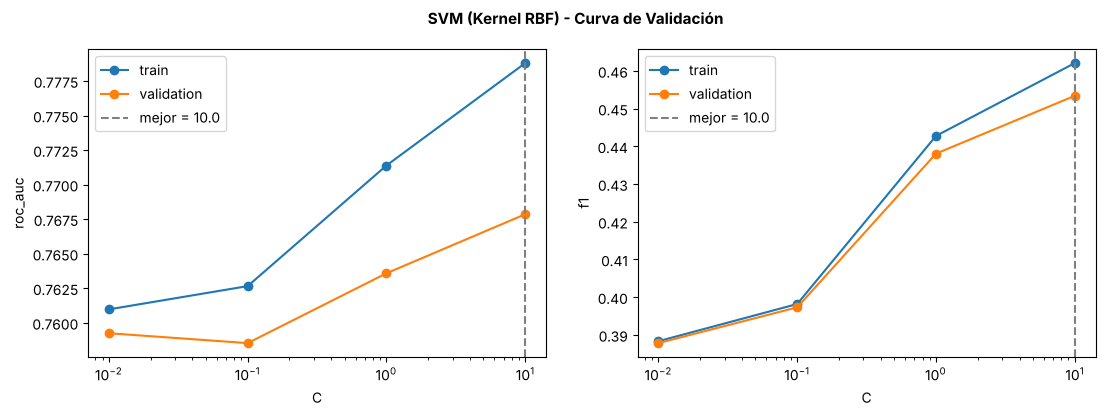

In [6]:
best_svm_c = plot_validation_curve(svm_curve, "C", "SVM (Kernel RBF) - Curva de Validación",
                                   "08_validation_curve_svm.png", log_scale=True)

## KNN: número de vecinos (set 3)
- **k pequeño:** frontera muy flexible, memoriza anomalías locales (sobreajuste).
- **k grande:** frontera más suave; demasiado grande favorece a la clase mayoritaria (subajuste).

In [7]:
knn_curve = evaluate_hyperparameter(
    "KNN", KNeighborsClassifier(),
    parameter_name="n_neighbors",
    parameter_values=[1, 5, 15, 31, 51, 101, 201, 401],
)
knn_curve.round(3)

n_neighbors = 1: completado


n_neighbors = 5: completado


n_neighbors = 15: completado


n_neighbors = 31: completado


n_neighbors = 51: completado


n_neighbors = 101: completado


n_neighbors = 201: completado


n_neighbors = 401: completado


,n_neighbors,train_roc_auc,validation_roc_auc,train_f1,validation_f1
0,1,0.760,0.605,0.573,0.298
1,5,0.827,0.714,0.465,0.340
2,15,0.842,0.749,0.373,0.328
3,31,0.833,0.761,0.331,0.317
4,51,0.817,0.765,0.324,0.318
5,101,0.801,0.766,0.318,0.316
6,201,0.789,0.770,0.317,0.317
7,401,0.784,0.773,0.317,0.317


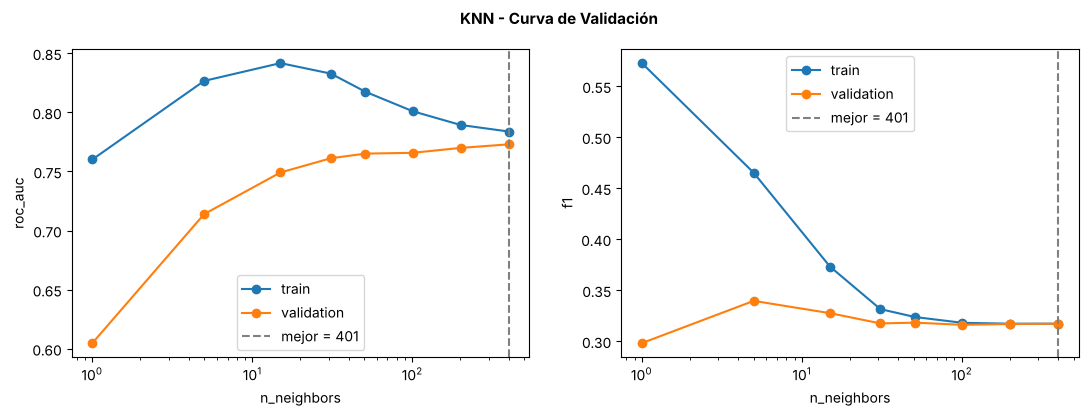

In [8]:
best_knn_neighbors = plot_validation_curve(knn_curve, "n_neighbors", "KNN - Curva de Validación",
                                           "09_validation_curve_knn.png", log_scale=True)

## Random Forest: profundidad máxima del árbol (set 1)
- **Profundidad baja:** subajuste.
- **Profundidad alta:** sobreajuste (los árboles memorizan el ruido de train).

In [9]:
random_forest_curve = evaluate_hyperparameter(
    "Random Forest", RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    parameter_name="max_depth",
    parameter_values=[2, 4, 6, 8, 10, 12, 15, 20, 25],
)
random_forest_curve.round(3)

max_depth = 2: completado


max_depth = 4: completado


max_depth = 6: completado


max_depth = 8: completado


max_depth = 10: completado


max_depth = 12: completado


max_depth = 15: completado


max_depth = 20: completado


max_depth = 25: completado


,max_depth,train_roc_auc,validation_roc_auc,train_f1,validation_f1
0,2,0.784,0.783,0.363,0.363
1,4,0.796,0.791,0.454,0.454
2,6,0.806,0.796,0.464,0.462
3,8,0.826,0.798,0.475,0.465
4,10,0.857,0.796,0.500,0.467
5,12,0.892,0.786,0.536,0.466
6,15,0.932,0.764,0.576,0.424
7,20,0.955,0.736,0.582,0.356
8,25,0.957,0.727,0.581,0.341


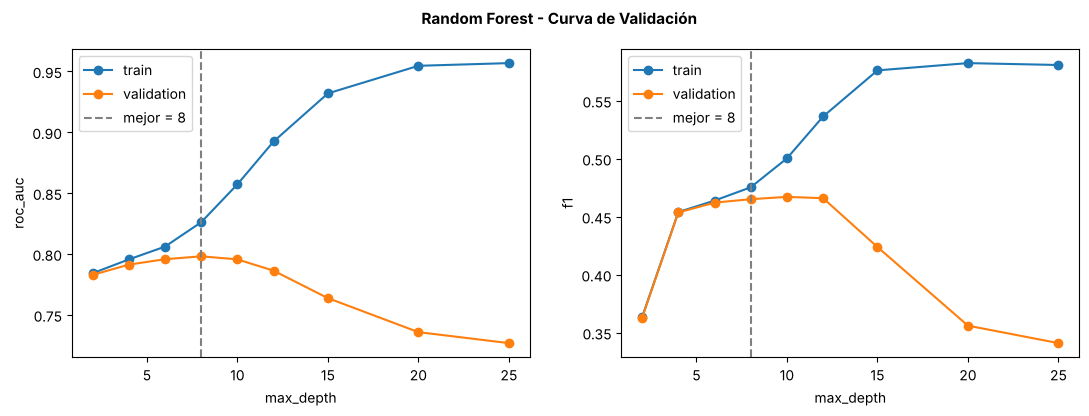

In [10]:
best_random_forest_depth = plot_validation_curve(random_forest_curve, "max_depth",
                                                 "Random Forest - Curva de Validación",
                                                 "10_validation_curve_random_forest.png")

## Resumen de los modelos ajustados (mejores valores en validación)

In [11]:
tuned_results = pd.DataFrame([
    {"classifier": f"SVM (C={best_svm_c})",
     **svm_curve.loc[svm_curve["C"] == best_svm_c].iloc[0, 1:]},
    {"classifier": f"KNN (k={best_knn_neighbors})",
     **knn_curve.loc[knn_curve["n_neighbors"] == best_knn_neighbors].iloc[0, 1:]},
    {"classifier": f"Random Forest (max_depth={best_random_forest_depth})",
     **random_forest_curve.loc[random_forest_curve["max_depth"] == best_random_forest_depth].iloc[0, 1:]},
]).set_index("classifier")
tuned_results.round(3)

,train_roc_auc,validation_roc_auc,train_f1,validation_f1
classifier,,,,
SVM (C=10.0),0.779,0.768,0.462,0.453
KNN (k=401),0.784,0.773,0.317,0.317
Random Forest (max_depth=8),0.826,0.798,0.475,0.465


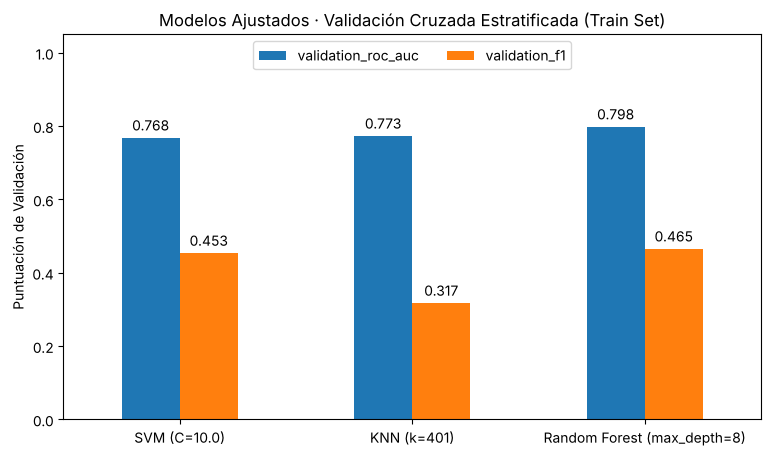

In [12]:
ax = tuned_results[["validation_roc_auc", "validation_f1"]].plot(kind="bar", figsize=(9, 5), rot=0)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_ylim(0, 1.05)
ax.legend(loc="upper center", ncols=2)
ax.set_xlabel("")
ax.set_ylabel("Puntuación de Validación")
ax.set_title("Modelos Ajustados · Validación Cruzada Estratificada (Train Set)")
plt.savefig(FIGURES_PATH / "11_tuned_models_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Conclusiones del Paso 3
- **Random Forest:** subajuste con `max_depth` 2–4 (train ≈ validación ≈ 0.78–0.79); óptimo en **`max_depth = 8`** (ROC-AUC 0.798, F1 0.465); sobreajuste desde 12–15 (con 25: 0.957 train vs. 0.727 validación).
- **SVM:** con 7 variables casi no sobreajusta; aumentar C mejora levemente (0.759 → 0.768). El mejor valor (C = 10) está en el extremo de la grilla: valores mayores aumentan mucho el costo computacional.
- **KNN:** k = 1 sobreajusta (validación 0.605). Al aumentar k sube el ROC-AUC (0.773 con k = 401) pero el F1 cae a 0.317: con vecindarios grandes vota casi siempre la clase mayoritaria.
- Se selecciona **Random Forest (`max_depth = 8`)**, el mejor en ambas métricas, como modelo final del **Paso 4**.